# Visualizing Cycle Checking Strategies: Maze

Cycles are an issue with DFS and we need cycle checking.



# Code

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


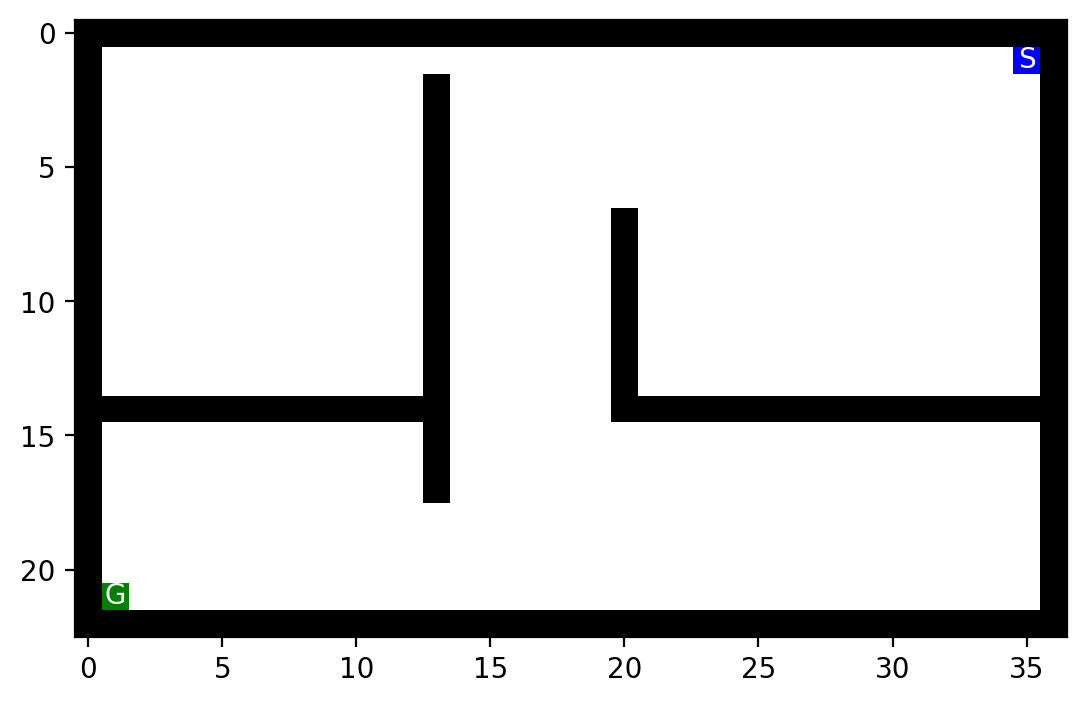

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np


#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts

# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)


## DFS Cycle checking option 1: Check the path

Do not expand nodes for states that are already in the current path. It works like this:

* Expand puts all new states into the frontier.
* When a state is taken from the frontier then we check if we already have a node for this state in the current path from the root node. If so,
then we ignore the state and pick the next one from the frontier. 
hen we try to add a frontier node to the current path then
we check if the state already exists in the path. 

Turns out that this does not manage the frontier well because there are cases where the same state gets added multiple times to the frontier leading to clearing 
space and then re-exploring it over and over again.


In [3]:
%time result = ts.DFS(maze, vis = False, animation = True, max_tries=500, frontier_option = 3)

ts.animate_maze(result)

CPU times: user 14.7 ms, sys: 0 ns, total: 14.7 ms
Wall time: 14.6 ms
No solution found.


The room looks solid red, but there are still some of the red points left in the frontier!

## DFS Cycle checking option 2: Check the path + don't add states that are already in the frontier a second time.

This unfortunately does not work and produces still an infinite loop if there are any open spaces in the maze!

In [4]:
%time result = ts.DFS(maze, animation = True, max_tries = 500, frontier_option = 2)

ts.animate_maze(result)

CPU times: user 17.1 ms, sys: 0 ns, total: 17.1 ms
Wall time: 16.8 ms
No solution found.


Note that there are still frontier entires (orange squares) left when DFS removed a completed branch from memory (squares that turn white). This is a problem, since DFS will explore them again leading to an infinite loop.



## DFS Cycle checking option 3: Check the path + fix the frontier by moving found states to the top of the frontier stack

Increasing the priority of a frontier entry when we see it again solves this issue (i.e., remove it from the stack and put it again on the top). 
Note that there are no orange squares left when DFS removes a path from memory so it knows that this part of the maze is done.

In [5]:
%time result = ts.DFS(maze, vis = False, animation = True, max_tries=500, frontier_option = 1)

ts.animate_maze(result)

CPU times: user 9.22 ms, sys: 4.13 ms, total: 13.4 ms
Wall time: 13.2 ms
Path length: 54
Reached squares: 211
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S']


---
# BÀI 7. KIỂM TRA CHU TRÌNH TRONG DFS — BÀI LÀM

**Nguồn bài:** `05_Maze_Example-Animation_Cycle_checking.ipynb` và hướng dẫn Lab02. Giữ lại toàn bộ 12 cell gốc phía trên.

**Lưu ý về triển khai:** `tree_search_solution.py` của giảng viên không được công bố trong notebook gốc. Bộ nộp này có **phiên bản cài đặt minh họa độc lập**, mô phỏng ba lựa chọn như Markdown gốc mô tả. Vì vậy, các số đo bên dưới là của phiên bản minh họa này, không phải của mã nguồn chưa công bố. Trong gói đã kèm module và `open_maze.txt` để chạy lại được.

### Mục tiêu thí nghiệm
1. Thử ba phương án kiểm tra chu trình trên `open_maze` với cùng thứ tự xét hướng `NESW`.
2. Đo **iterations** (số lần `pop()` từ stack, kể cả nút bị loại do chu trình), **expanded** (nút thực sự được mở rộng), **repeated expansions** (lượt mở rộng vượt quá số trạng thái phân biệt), **max frontier** và **trạng thái kết thúc**.
3. Quan sát việc trạng thái xuất hiện lặp lại trong frontier, dù việc đi vòng trên đường đi hiện tại đã được ngăn chặn.


## 7.1. Cơ sở lý thuyết — ba phương án cycle checking

| Phương án theo tài liệu | Tham số trong notebook | Cách xử lý |
|---|---:|---|
| **1. Kiểm tra đường đi hiện tại** | `frontier_option=3` | Loại nút nếu trạng thái của nó trùng với một tổ tiên; **không loại bản sao có ở frontier**. |
| **2. Kiểm tra đường đi + tránh trùng frontier** | `frontier_option=2` | Tương tự 1 và bỏ qua một trạng thái nếu đã có nút tương ứng trong stack. Nút bị bỏ qua có thể cần được xét lại khi một nhánh kết thúc. |
| **3. Kiểm tra đường đi + cập nhật thứ tự frontier** | `frontier_option=1` | Nếu trạng thái đã ở stack, **loại entry cũ và đưa entry mới với liên kết cha hiện tại lên đầu stack** (cuối `list` Python). Điều này giúp duy trì ưu tiên theo nhánh DFS. |

Cần phân biệt **kiểm tra chu trình trên một đường đi** với **global visited/reached**: kiểm tra đường đi chỉ ngăn đi vòng về các nút tổ tiên, còn một trạng thái vẫn có thể được khám phá nhiều lần ở các nhánh khác nhau. Kiểm tra frontier giúp giảm nút trùng đang chờ nhưng không đồng nghĩa loại mọi lần thăm lại trên toàn bộ cây tìm kiếm.


## 7.2. Chuẩn bị dữ liệu `open_maze` và thiết lập thí nghiệm

Đọc dữ liệu bằng hàm `maze_helper.parse_maze`, xác định vị trí `S` và `G`. Đặt `max_tries=500` giống các cell gốc để so sánh công bằng. Ở đây mỗi **iteration** ứng với một lượt lấy nút khỏi stack; giới hạn ngăn quá trình duyệt kéo dài khi có nhiều trạng thái lặp.


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import maze_helper as mh
import tree_search_solution as ts

with open('open_maze.txt', 'r', encoding='utf-8') as f:
    open_maze_b7 = mh.parse_maze(f.read())

start_b7 = mh.find_pos(open_maze_b7, 'S')
goal_b7 = mh.find_pos(open_maze_b7, 'G')
valid_b7 = int(np.count_nonzero(open_maze_b7 != 'X'))
print('Shape:', open_maze_b7.shape, '| Walkable states:', valid_b7)
print('Start:', start_b7, '| Goal:', goal_b7)
assert start_b7 == (1, 35) and goal_b7 == (21, 1)
ts.set_order('NESW')

Shape: (23, 37) | Walkable states: 684
Start: (np.int64(1), np.int64(35)) | Goal: (np.int64(21), np.int64(1))


## 7.3. Chạy ba phương án kiểm tra chu trình

Tham số `frontier_option` dùng đúng quy ước `3 → 2 → 1` của notebook gốc. Các lần chạy đều khởi tạo frontier mới, dùng cùng mê cung và giới hạn. Trường `stopped_by_limit=True` **không phải** bằng chứng thuật toán sẽ lặp vô hạn: chỉ chứng tỏ chưa tìm ra đích trong 500 lượt lấy nút.


In [7]:
MAX_TRIES_B7 = 500
OPTIONS_B7 = [
    ('1. Path only', 3),
    ('2. Path + no duplicate frontier', 2),
    ('3. Path + move entry to stack top', 1),
]
results_b7 = {}
rows_b7 = []
for label, option in OPTIONS_B7:
    ts.set_order('NESW')
    r = ts.DFS(open_maze_b7, frontier_option=option,
               max_tries=MAX_TRIES_B7, animation=False)
    results_b7[option] = r
    rows_b7.append({
        'Phuong_an': label, 'frontier_option': option,
        'iterations': r['iterations'],
        'expanded': r['n_expanded'],
        'unique_expanded': r['distinct_expanded'],
        'repeated_expansions': r['repeated_expansions'],
        'max_frontier': r['max_frontier'],
        'max_duplicate_entries': r['max_duplicate_entries'],
        'cycle_pruned': r['cycle_pruned'],
        'frontier_skipped': r['frontier_skipped'],
        'frontier_promoted': r['frontier_promoted'],
        'found': r['path'] is not None,
        'path_cost': r['path_cost'],
        'stopped_by_limit': r['stopped_by_limit'],
    })
comparison_b7 = pd.DataFrame(rows_b7)
display(comparison_b7)
assert results_b7[1]['path'] is not None
assert results_b7[1]['path_cost'] == 54
assert results_b7[3]['max_duplicate_entries'] > 0
assert results_b7[2]['max_duplicate_entries'] == 0
assert results_b7[1]['max_duplicate_entries'] == 0


,Phuong_an,frontier_option,iterations,expanded,unique_expanded,repeated_expansions,max_frontier,max_duplicate_entries,cycle_pruned,frontier_skipped,frontier_promoted,found,path_cost,stopped_by_limit
0,1. Path only,3,500,221,179,42,328,129,279,0,0,False,NaN,True
1,2. Path + no duplicate frontier,2,500,250,116,134,162,0,250,231,0,False,NaN,True
2,3. Path + move entry to stack top,1,434,211,211,0,143,0,222,0,201,True,54.0,False


## 7.4. Phân tích số lần lặp và trạng thái bị khám phá lại

- `iterations`: tổng số lần thực hiện `stack.pop()` trước khi tìm được đích hoặc dừng vì `max_tries`, bao gồm cả lượt bị loại do chu trình.
- `expanded`: số lượt mở rộng thật sự (có thể chứa nhiều lần của cùng một trạng thái).
- `repeated_expansions = expanded − unique_expanded`: số **lượt mở rộng trùng**, không phải số trạng thái trùng độc lập.
- `max_duplicate_entries`: số bản sao dư thừa lớn nhất trong frontier tại một thời điểm.
- `frontier_promoted`: số lần phương án 3 chuyển entry đến đỉnh stack.

Một trạng thái có thể bị mở rộng lặp lại mà frontier tại mỗi thời điểm **không có nút trùng**. Do đó, `repeated_expansions` và `max_duplicate_entries` phải được quan sát riêng.


,Phuong_an,iterations,expanded,unique_expanded,repeated_expansions,max_frontier,max_duplicate_entries,found,path_cost
0,1. Path only,500,221,179,42,328,129,False,NaN
1,2. Path + no duplicate frontier,500,250,116,134,162,0,False,NaN
2,3. Path + move entry to stack top,434,211,211,0,143,0,True,54.0


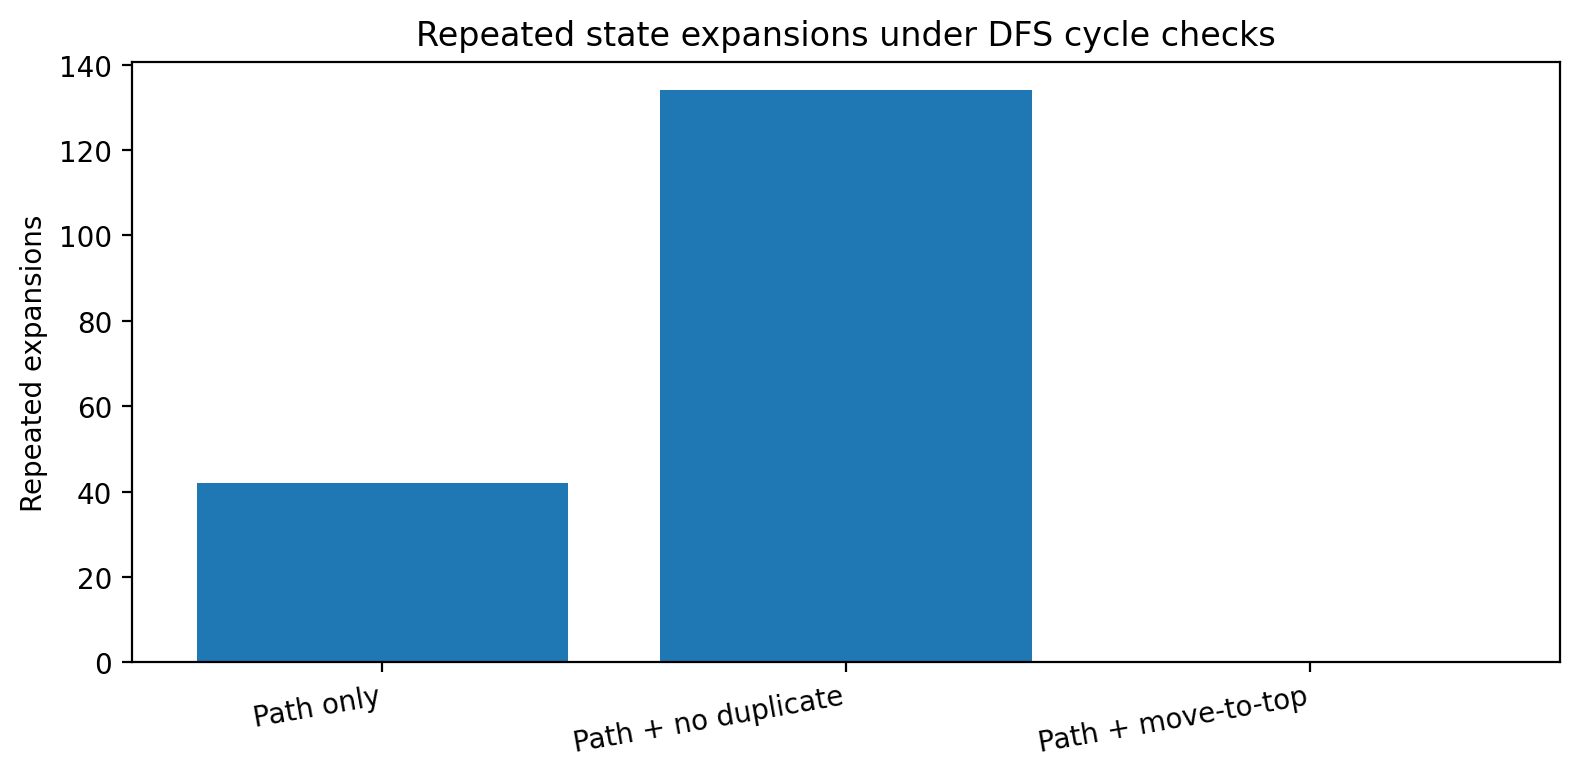

In [8]:
display(comparison_b7[[
    'Phuong_an', 'iterations', 'expanded', 'unique_expanded',
    'repeated_expansions', 'max_frontier', 'max_duplicate_entries',
    'found', 'path_cost'
]])

fig, ax = plt.subplots(figsize=(8, 4))
labels = ['Path only', 'Path + no duplicate', 'Path + move-to-top']
ax.bar(labels, comparison_b7['repeated_expansions'])
ax.set_ylabel('Repeated expansions')
ax.set_title('Repeated state expansions under DFS cycle checks')
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

## 7.5. Sự thay đổi kích thước frontier theo quá trình duyệt

Đường biểu diễn lấy từ log `trace` sau mỗi lần mở rộng; các lượt bị loại do chu trình không tạo ra điểm log. `max_frontier` là giá trị lớn nhất đo được qua toàn bộ vòng lặp, không nhất thiết bằng kích thước frontier tại bước cuối.


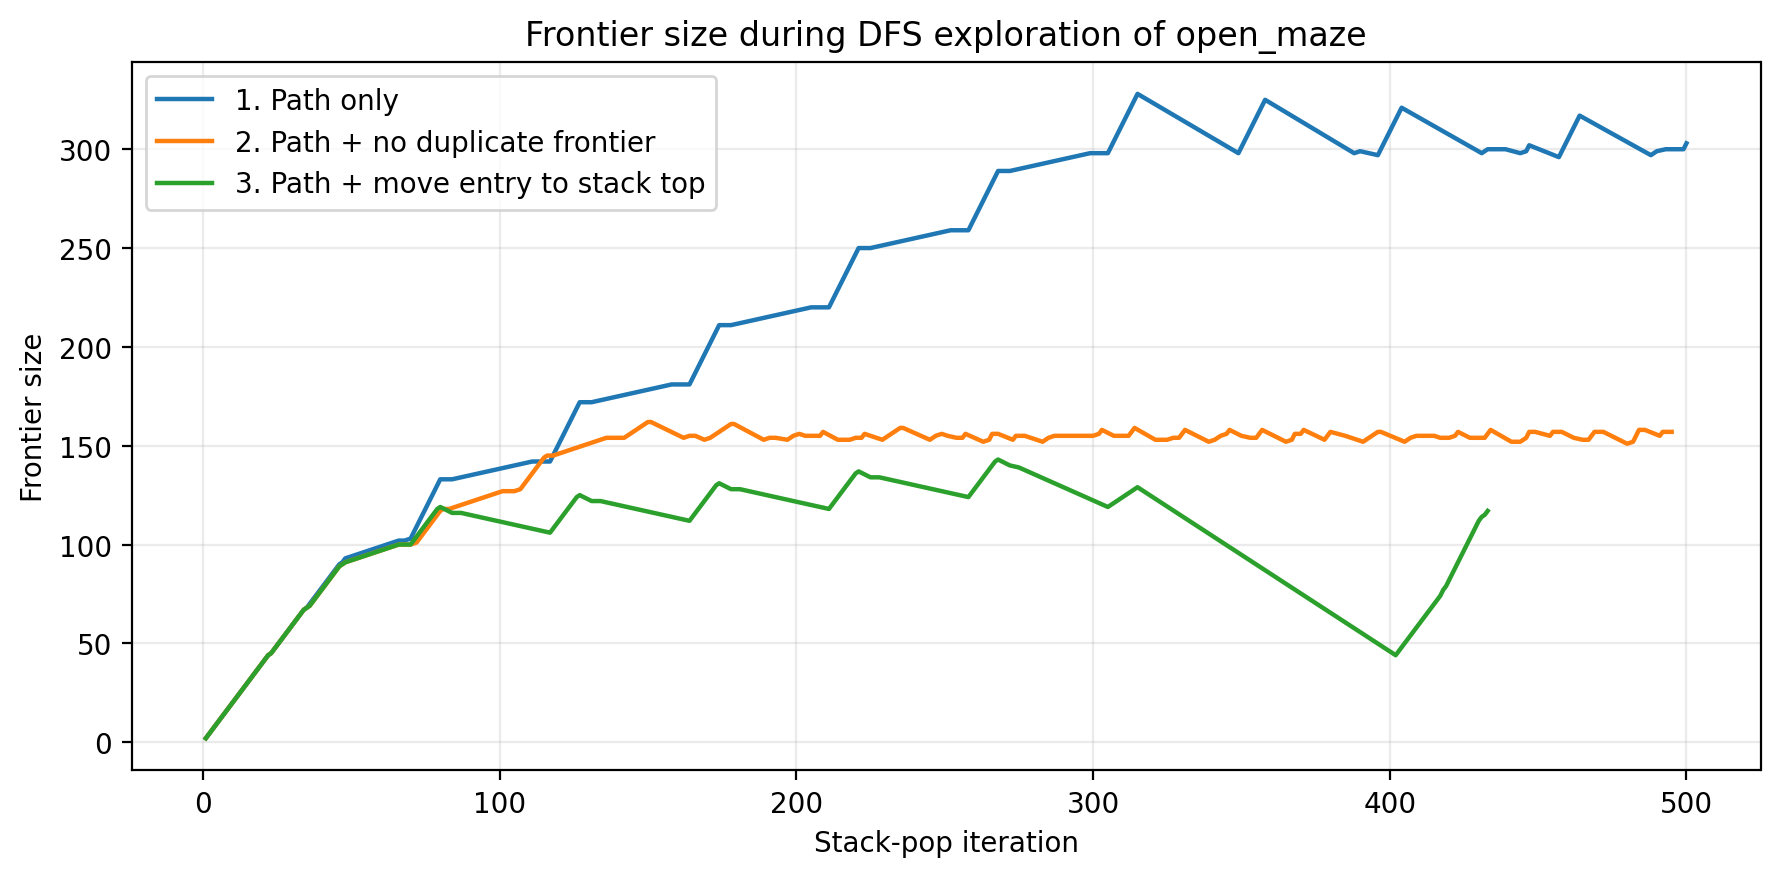

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for label, option in OPTIONS_B7:
    tr = results_b7[option]['trace']
    ax.plot([v['step'] for v in tr], [v['frontier_size'] for v in tr],
            label=label, linewidth=1.6)
ax.set_title('Frontier size during DFS exploration of open_maze')
ax.set_xlabel('Stack-pop iteration')
ax.set_ylabel('Frontier size')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 7.6. Trực quan hóa vùng trạng thái được mở rộng

Bản đồ dưới đây thống kê **số lần mở rộng từng trạng thái** trong từng phương án. Những ô có giá trị lớn hơn 1 chứng tỏ có tái khám phá. Bản đồ chỉ minh họa lượt mở rộng; `S` và `G` được đánh dấu riêng, các ô tường bị che.


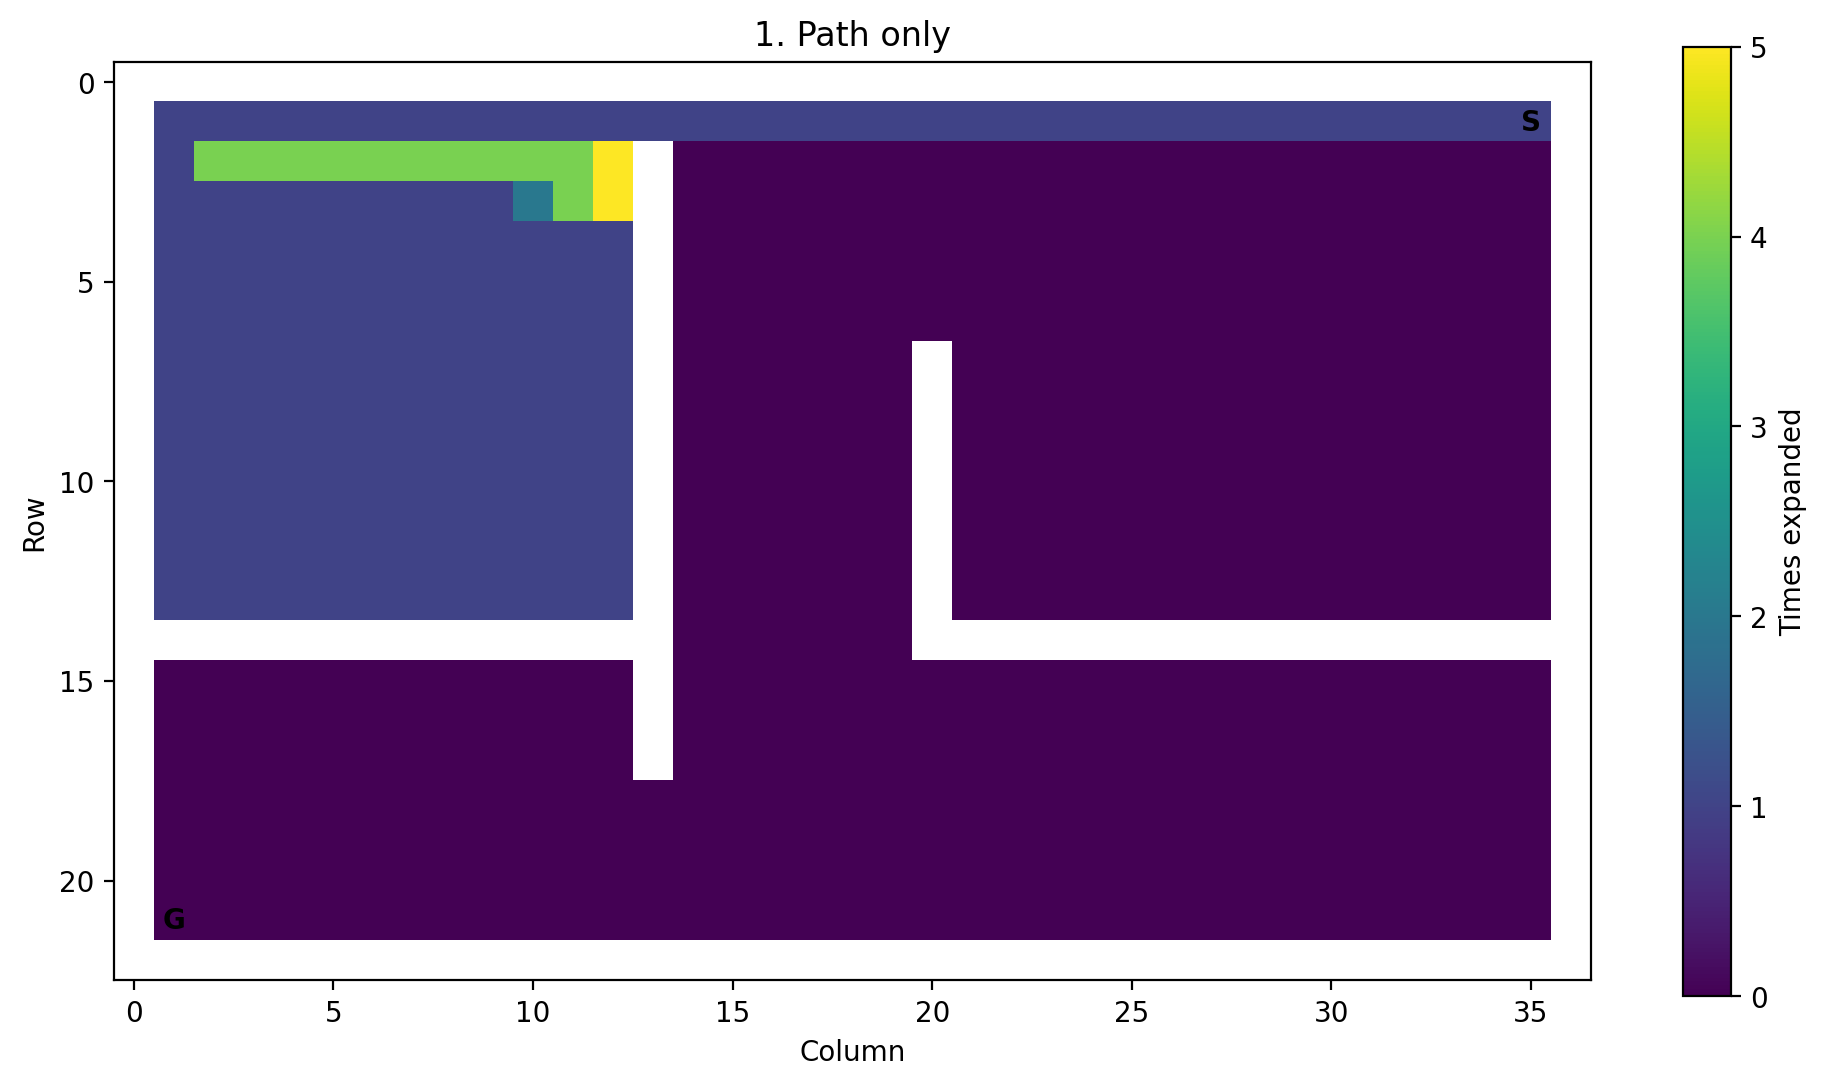

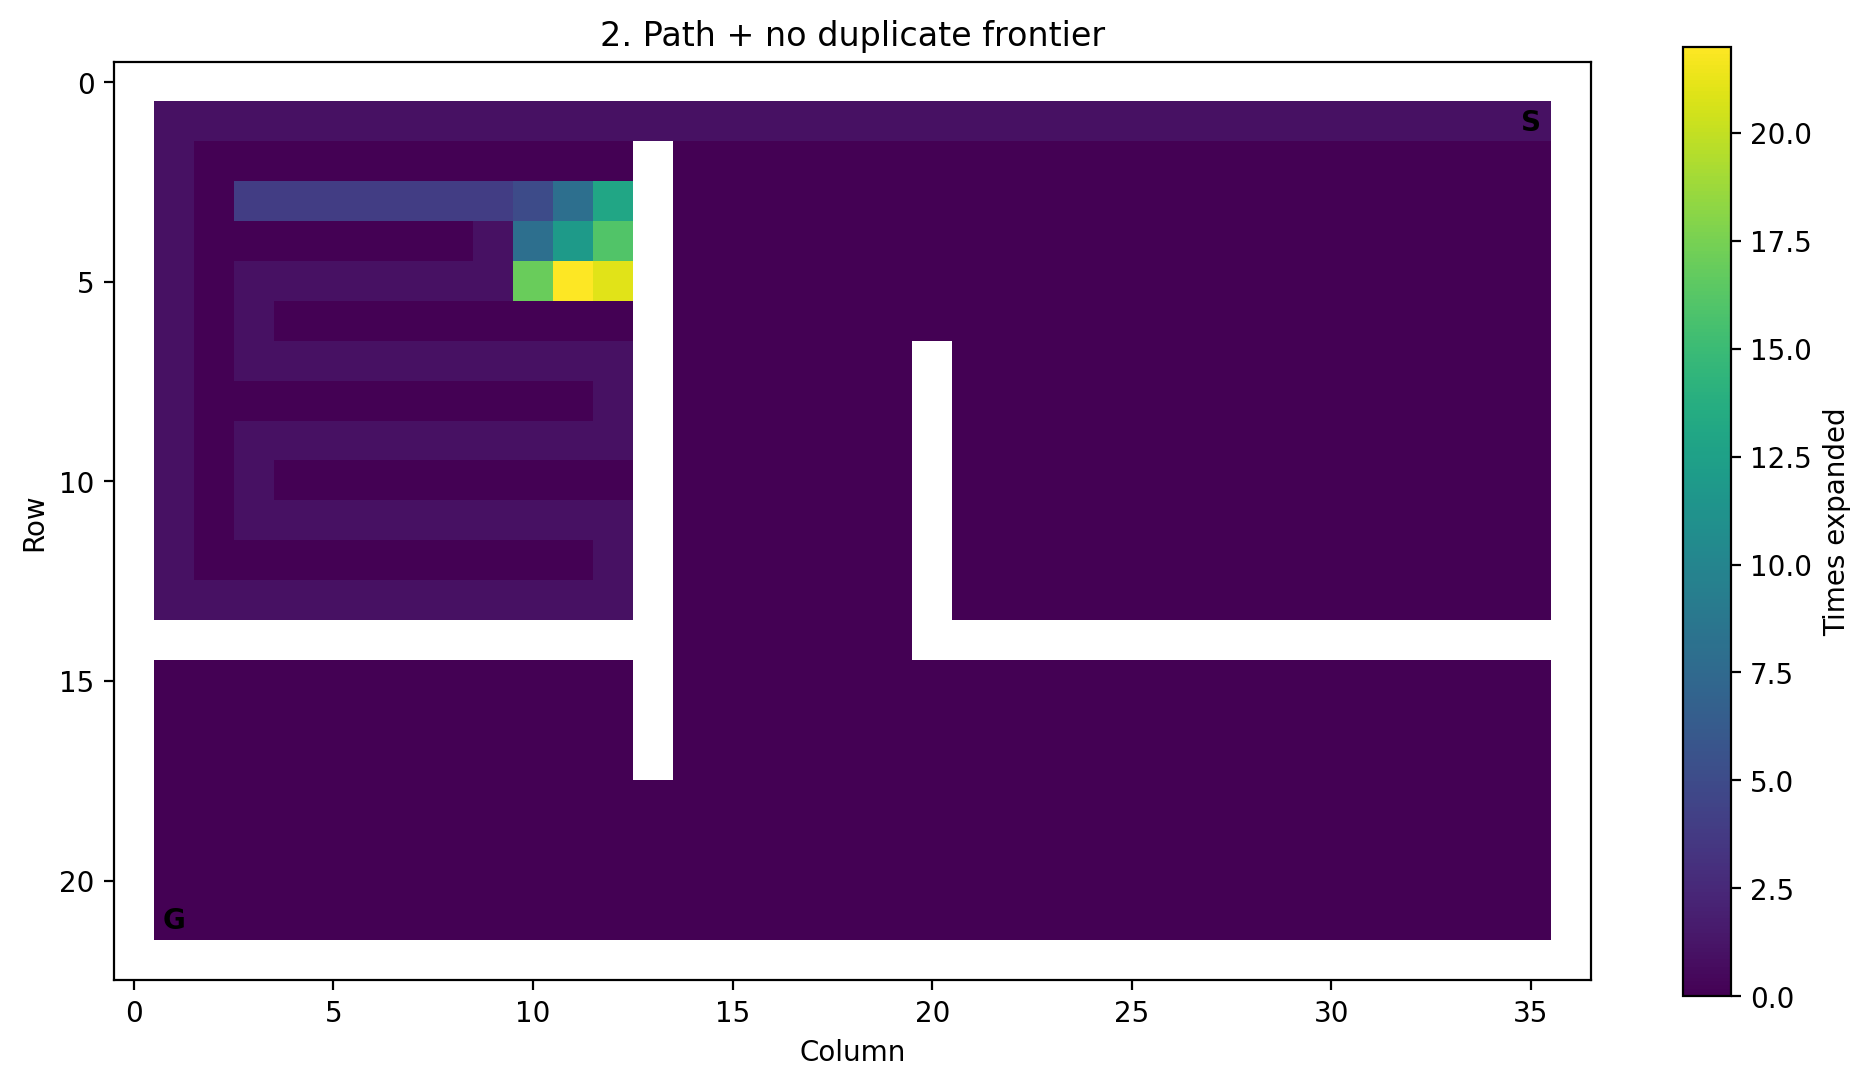

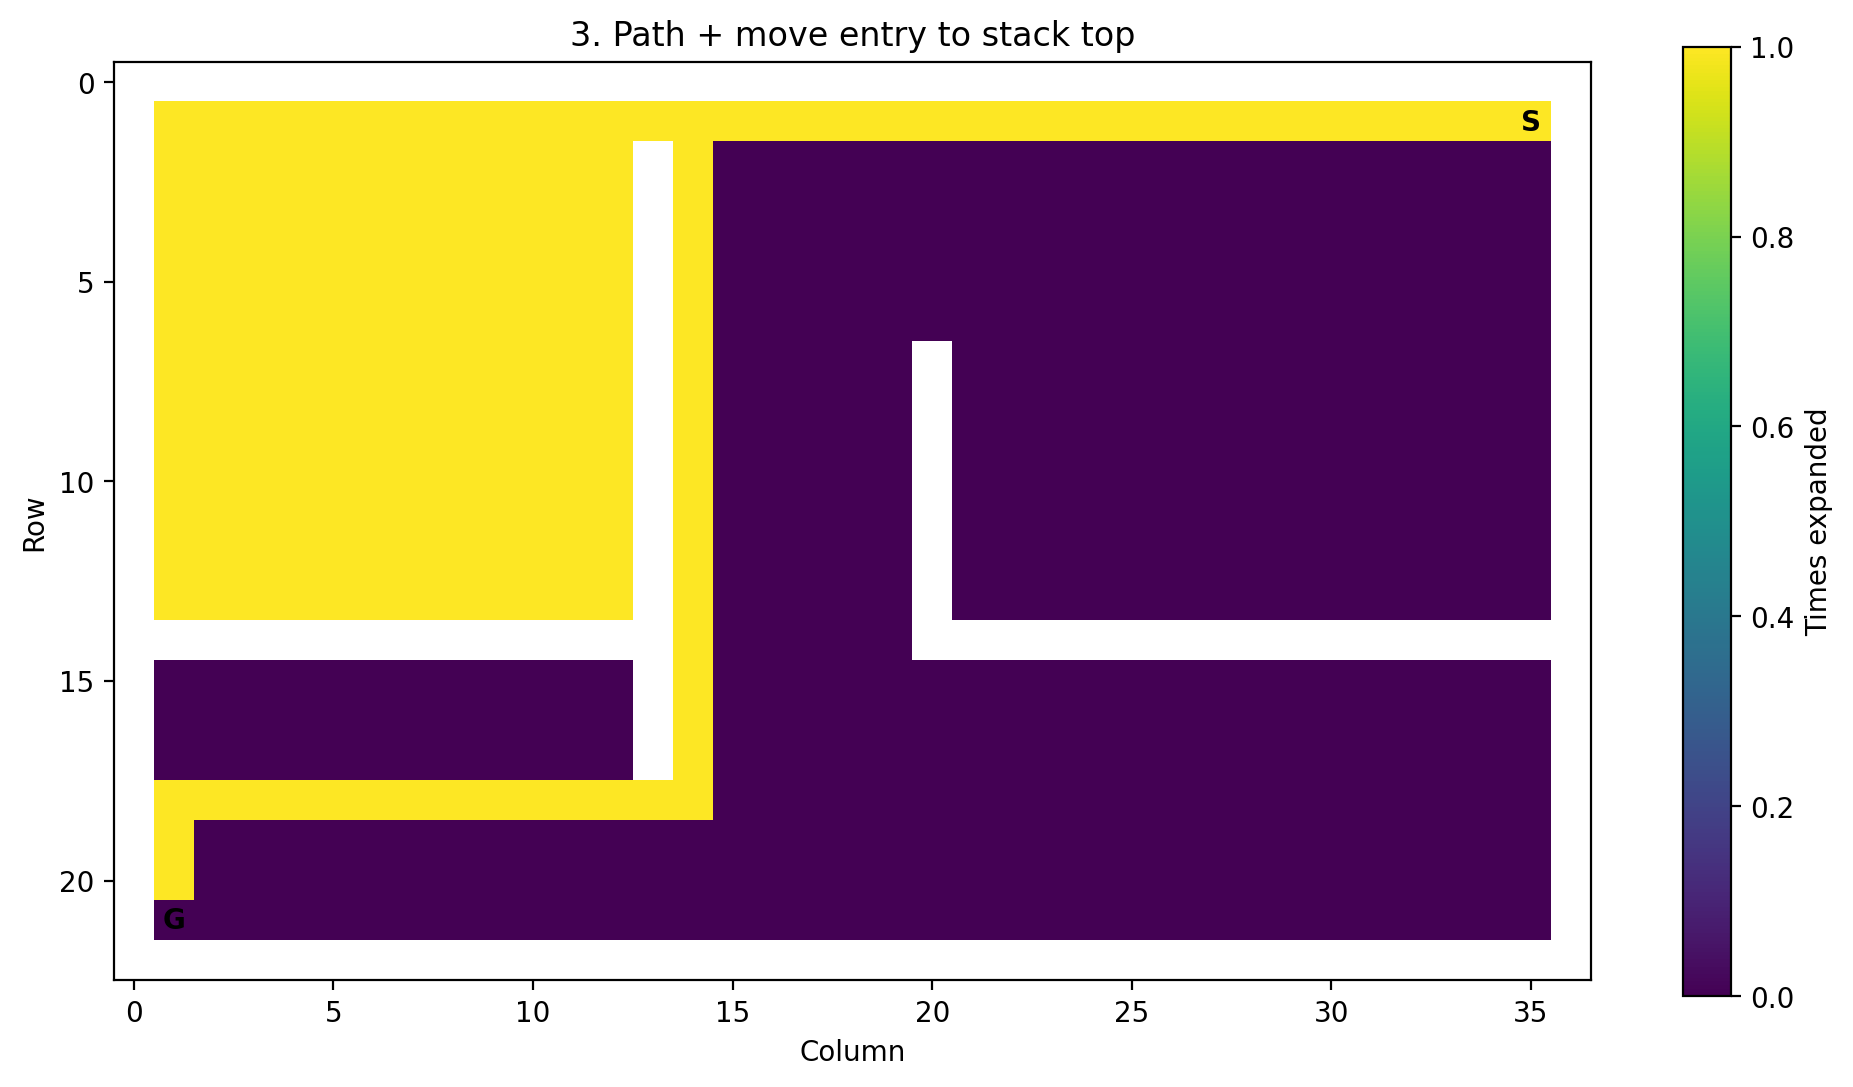

In [10]:
def show_expansion_counts_b7(maze, result, title):
    frequencies = np.zeros(maze.shape, dtype=int)
    for pos in result['expanded_order']:
        frequencies[pos] += 1
    masked = np.ma.masked_where(maze == 'X', frequencies)
    fig, ax = plt.subplots(figsize=(10, 5.4))
    im = ax.imshow(masked, interpolation='nearest')
    start, goal = mh.find_pos(maze, 'S'), mh.find_pos(maze, 'G')
    ax.text(start[1], start[0], 'S', ha='center', va='center', fontweight='bold')
    ax.text(goal[1], goal[0], 'G', ha='center', va='center', fontweight='bold')
    fig.colorbar(im, ax=ax, label='Times expanded')
    ax.set_title(title)
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')
    plt.tight_layout()
    plt.show()

for label, option in OPTIONS_B7:
    show_expansion_counts_b7(open_maze_b7, results_b7[option], label)

## 7.7. Quan sát đường đi của phương án 3

Phương án 3 tìm thấy lời giải trong giới hạn 500 lần lấy nút. Đường đi và chi phí được đọc trực tiếp từ kết quả trả về. Tạo **bản sao** của mê cung để đánh dấu đường đi, không thay đổi dữ liệu đầu vào.


Found: True
Path cost: 54
Steps: 54
Actions: WWWWWWWWWWWWWWWWWWWWWSSSSSSSSSSSSSSSSSWWWWWWWWWWWWWSSS


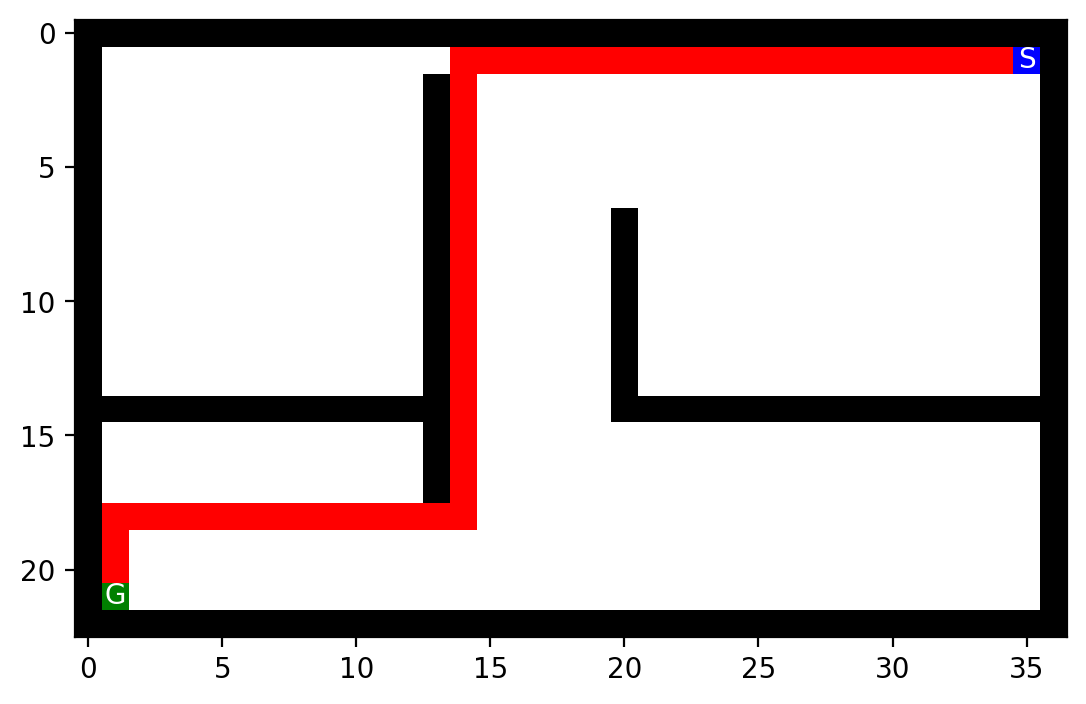

In [11]:
r3_b7 = results_b7[1]
print('Found:', r3_b7['path'] is not None)
print('Path cost:', r3_b7['path_cost'])
print('Steps:', len(r3_b7['actions']))
print('Actions:', ''.join(r3_b7['actions']))

marked_b7 = np.copy(open_maze_b7)
for pos in r3_b7['path'][1:-1]:
    if marked_b7[pos] == ' ':
        marked_b7[pos] = 'P'
mh.show_maze(marked_b7)
assert len(r3_b7['path']) - 1 == r3_b7['path_cost']

## 7.8. Nhận xét và kết luận (có thể đưa vào báo cáo)

**Phương án 1 — Kiểm tra đường đi hiện tại:** Kiểm tra một trạng thái có trùng với tổ tiên trên đường đi hiện tại hay không giúp tránh chu trình nội bộ trong cùng một nhánh DFS. Tuy nhiên, do không quản lý các nút trùng đang có trong frontier, nhiều bản sao của cùng trạng thái vẫn được thêm vào stack. Thực nghiệm cho thấy frontier có thể phình lớn, và một trạng thái có thể được mở rộng nhiều lần ở các nhánh khác nhau.

**Phương án 2 — Kiểm tra đường đi và loại trùng frontier:** Cơ chế này giảm các nút trùng tồn tại **đồng thời** trong frontier, từ đó giảm kích thước stack so với phương án 1 trong thí nghiệm. Tuy nhiên, khi một entry đã được lấy ra khỏi frontier, trạng thái ấy có thể được thêm lại theo các nhánh khác. Trong 500 lượt thử, số lần mở rộng lặp lại vẫn cao, minh họa rằng chỉ tránh trùng tại thời điểm đưa vào frontier chưa đủ để tránh tái khám phá.

**Phương án 3 — Kiểm tra đường đi và di chuyển entry lên đỉnh stack:** Khi một trạng thái xuất hiện lại trong lúc vẫn có nút tương ứng đang chờ trong frontier, thay vì bỏ qua hoặc tạo bản sao, ta xóa entry cũ và chèn entry mới lên đỉnh stack, cập nhật `parent`, `action`, `cost`. Cách quản lý này hỗ trợ tính liên tục của quá trình đi sâu và giảm lặp trạng thái trong thí nghiệm. Với giới hạn 500 lần `pop`, phương án này tìm được đường đi 54 bước.

**Kết luận:** Cycle checking là thành phần cần thiết khi sử dụng DFS trên không gian trạng thái có nhiều đường liên thông và chu trình. Kiểm tra đường đi giúp ngăn vòng lặp trên một nhánh, nhưng cơ chế quản lý frontier quyết định số trạng thái bị khám phá lại và mức bộ nhớ dùng cho stack. Hiệu quả của từng phương án phụ thuộc cấu trúc mê cung, thứ tự sinh trạng thái và cách cập nhật nút. Các kết quả trên chỉ được kết luận cho triển khai thí nghiệm được cung cấp.


## 7.9. Kiểm tra tính tái lập

Chạy tất cả các cell từ trên xuống với `open_maze.txt`, `maze_helper.py` và bản `tree_search_solution.py` kèm theo. Để đảm bảo so sánh công bằng, dùng `ts.set_order('NESW')` và `max_tries=500`. Số liệu có thể khác nếu bạn dùng mã nguồn chưa công bố của giảng viên hoặc thay đổi cách định nghĩa `iterations`.


In [12]:
assert set(comparison_b7['frontier_option']) == {1, 2, 3}
assert comparison_b7['iterations'].max() <= MAX_TRIES_B7
assert all(r['n_expanded'] >= r['distinct_expanded'] for r in results_b7.values())
assert results_b7[3]['stopped_by_limit']
assert results_b7[2]['stopped_by_limit']
assert not results_b7[1]['stopped_by_limit']
print('PASSED: 3 strategies, iteration cap, repeated-state metrics, path reconstruction.')

PASSED: 3 strategies, iteration cap, repeated-state metrics, path reconstruction.
